# 06 - Linear Regression Evaluation and Visualization

## Aim
Create a compact model-evaluation notebook for linear regression. The same fitted values are examined with MAE, MSE, RMSE, R² and residual plots.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Fit a baseline linear model

In [2]:
data = pd.read_csv("datasets/P176.txt", sep="\t")
X = data[["X"]]
y = data["Y"]

model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

print(f"Equation: y = {model.intercept_:.4f} + {model.coef_[0]:.4f}x")

Equation: y = 14.4481 + 0.1054x


## 3. Calculate evaluation metrics

In [3]:
metric_values = {
    "MAE": mean_absolute_error(y, y_pred),
    "MSE": mean_squared_error(y, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
    "R²": r2_score(y, y_pred),
}

for name, value in metric_values.items():
    print(f"{name:>4}: {value:.4f}")

 MAE: 16.1397
 MSE: 437.1876
RMSE: 20.9090
  R²: 0.7759


### Metric reminder
- **MAE**: average absolute prediction error.
- **MSE**: average squared error; large errors receive more weight.
- **RMSE**: square root of MSE, in the same units as the target.
- **R²**: proportion of target variation explained by the model.

## 4. Inspect residuals

In [4]:
residuals = y - y_pred
residual_table = pd.DataFrame({
    "X": X["X"],
    "Actual": y,
    "Predicted": y_pred,
    "Residual": residuals
})
residual_table.head(10)

,X,Actual,Predicted,Residual
0,294,30,45.424220,-15.424220
1,247,32,40.472249,-8.472249
2,267,37,42.579471,-5.579471
3,358,44,52.167330,-8.167330
4,423,47,59.015801,-12.015801
5,311,49,47.215359,1.784641
6,450,56,61.860551,-5.860551
7,534,62,70.710883,-8.710883
8,438,68,60.596218,7.403782
9,697,78,87.884741,-9.884741


## 5. Residual plot

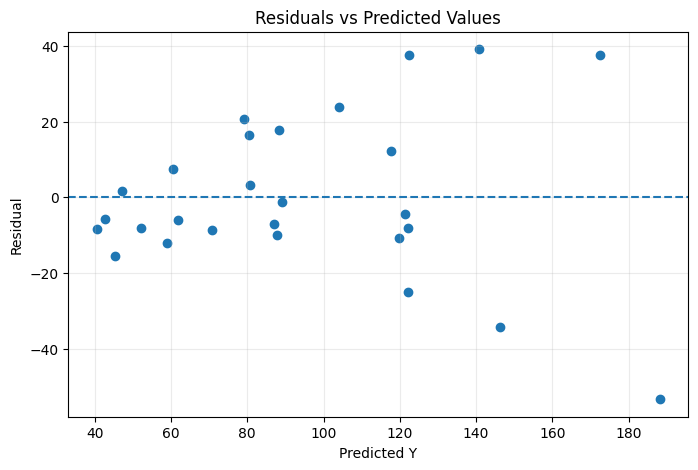

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0, linestyle="--", linewidth=1.5)
plt.xlabel("Predicted Y")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Values")
plt.grid(alpha=0.25)
plt.show()

## 6. Actual vs predicted plot

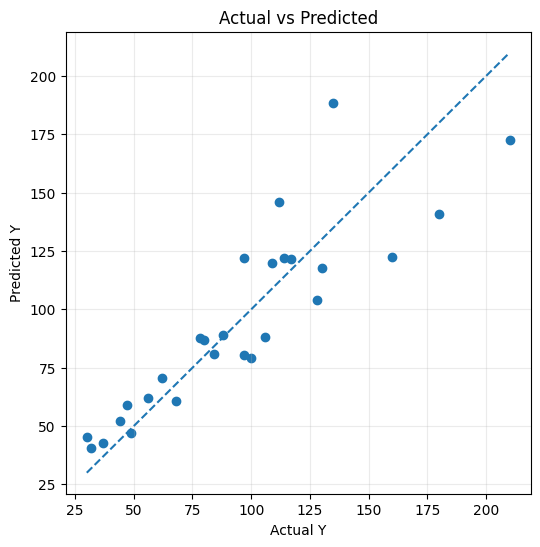

In [6]:
plt.figure(figsize=(6, 6))
plt.scatter(y, y_pred)
line_min = min(y.min(), y_pred.min())
line_max = max(y.max(), y_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--", linewidth=1.5)
plt.xlabel("Actual Y")
plt.ylabel("Predicted Y")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.25)
plt.show()

### Conclusion
A regression model should be judged with more than one number. Error metrics summarize prediction quality, while residual plots help reveal patterns that a single score may hide.